In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()


In [1]:
from pathlib import Path
import os

for directory in (
    "data/processed/gold/SV", "data/processed/subsets/SV",
    "outputs/predictions/SV", "outputs/evaluations/SV",
    "outputs/settings", "outputs/embeddings/subtask1_embedding_cache/SV",
    "outputs/exports",
):
    Path(directory).mkdir(parents=True, exist_ok=True)

# Locate the checkout in PyCharm, Jupyter, or Colab.
# candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / "semantic-change-over-time"]
# PROJECT_ROOT = next(
#     (path for path in candidates
#      if (path / "baselines_1.ipynb").is_file() and (path / "data/raw").is_dir()),
#     None,
# )
# if PROJECT_ROOT is None:
#     raise FileNotFoundError("Open the project checkout first; see README.md for Colab setup.")
# os.chdir(PROJECT_ROOT)
#
# for directory in (
#     "data/processed/gold/SV", "data/processed/subsets",
#     "outputs/predictions", "outputs/evaluations", "outputs/settings",
#     "outputs/embeddings", "outputs/exports",
# ):
#     Path(directory).mkdir(parents=True, exist_ok=True)
#
# print("Project:", PROJECT_ROOT)

Cloning into 'semantic-change-over-time'...
remote: Enumerating objects: 4771, done.
remote: Counting objects: 100% (4771/4771), done.
remote: Compressing objects: 100% (2438/2438), done.
remote: Total 4771 (delta 2324), reused 4771 (delta 2324), pack-reused 0 (from 0)
Receiving objects: 100% (4771/4771), 31.13 MiB | 38.09 MiB/s, done.
Resolving deltas: 100% (2324/2324), done.


## creating dataframe

In [2]:
import pandas as pd

folder = "data/raw/development-swedish/"
df = pd.read_json(folder + "usages.jsonl", lines=True)
df.head()

,word,sentence_id,text,pos,period_label,start,end,year
0,kvinna,137d9286_62_69,nesliga lif medelst sjelfmord ; och ett stort ...,NN,1880-1883,62,69,1883
1,kvinna,b382a5e9_92_98,"— Jag sov ; jag väcktes av en kylande känsla ,...",NN,1912-1915,92,98,1914
2,kvinna,28ffffe7_42_50,"orden , så mycken fasthet öfver den gamla kvin...",NN,1880-1883,42,50,1883
3,kvinna,3754909a_117_124,Dessa klubbar ha anordnat sällskapliga samkväm...,NN,1912-1915,117,124,1913
4,kvinna,59ebb00_32_39,Den avvisningshotade eritranska kvinnan Abiba ...,NN,2006-2007,32,39,2007


## baselines, grabbing grading scale

In [6]:
import shutil
import sys

EVALUATOR_DIR = PROJECT_ROOT / "src/evaluation/semeval2027-task3"
BCUBED_DIR = PROJECT_ROOT / "src/evaluation/python-bcubed"
if not (EVALUATOR_DIR / "evaluation.py").is_file() or not (BCUBED_DIR / "bcubed").is_dir():
    raise FileNotFoundError("Set up the competition evaluator using the commands in README.md.")
sys.path.insert(0, str(BCUBED_DIR))
sys.path.insert(0, str(EVALUATOR_DIR))

for source in (PROJECT_ROOT / "data/raw/development-swedish").glob("subtask*.jsonl"):
    shutil.copy2(source, PROJECT_ROOT / "data/processed/gold/SV" / source.name)

Cloning into 'semeval2027-task3'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 37 (delta 14), reused 23 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 1.76 MiB | 29.13 MiB/s, done.
Resolving deltas: 100% (14/14), done.
Cloning into 'python-bcubed'...
remote: Enumerating objects: 82, done.
remote: Total 82 (delta 0), reused 0 (delta 0), pack-reused 82 (from 1)
Receiving objects: 100% (82/82), 19.88 KiB | 6.63 MiB/s, done.
Resolving deltas: 100% (38/38), done.


## Subtask 1a: Grouping word usages by meaning (Andrea testing)

### Attempt 1: XLM-RoBERTa

In [12]:
%pip install -q transformers sentencepiece scikit-learn

Note: you may need to restart the kernel to use updated packages.


#### Load XLM-RoBERTa and its tokenizer for word embeddings.

In [13]:
import torch
from transformers import AutoTokenizer, AutoModel

if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

model_name = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)

model = AutoModel.from_pretrained(model_name).to(device).eval()

/Users/kmonroygill/Documents/Conda Environments/fall2026/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1112 00:03:51.066000 30297 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6906.86it/s]
[transformers] XLMRobertaModel LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if

#### Get a vector for each target word using its sentence context.

In [14]:
def get_word_vector(row):
    sentence = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    encoded = tokenizer(
        sentence,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    target_tokens = []
    for i, (token_start, token_end) in enumerate(offsets):
        if token_end > token_start and token_start < end and token_end > start:
            target_tokens.append(i)

    if not target_tokens:
        raise ValueError(f"Target word not found: {row['sentence_id']}")

    encoded = encoded.to(device)

    with torch.no_grad():
        output = model(**encoded)

    target_vectors = output.last_hidden_state[0, target_tokens]
    vector = target_vectors.mean(dim=0)

    return vector.cpu().numpy()

#### Start by extracting vectors for all usages of kvinna.

In [15]:
import numpy as np
from tqdm.auto import tqdm

word_data = df.loc[df["word"] == "kvinna"].copy()

vectors = []
for _, row in tqdm(word_data.iterrows(), total=len(word_data)):
    vectors.append(get_word_vector(row))

word_vectors = np.stack(vectors)

100%|██████████| 290/290 [01:00<00:00,  4.76it/s]


#### Try 2–6 clusters and select the number with the highest silhouette score.

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

scaled_vectors = normalize(word_vectors)

scores = {}
cluster_labels = {}

for k in range(2, 7):
    labels = KMeans(
        n_clusters=k, n_init=20, random_state=42
    ).fit_predict(scaled_vectors)

    scores[k] = silhouette_score(scaled_vectors, labels)
    cluster_labels[k] = labels

best_k = max(scores, key=scores.get)
word_data["cluster"] = cluster_labels[best_k]

word_data["cluster"].value_counts()

cluster
1    108
5     74
4     69
3     26
2      8
0      5
Name: count, dtype: int64

#### Compare our clusters with the single-cluster baseline using BCubed F1.

In [17]:
from pathlib import Path
from evaluation import evaluate_subtask1

word_gold = pd.read_json("../data/processed/gold/SV/subtask1.jsonl", lines=True)
word_gold = word_gold.loc[word_gold["word"] == "kvinna"]
word_gold.to_json("data/processed/subsets/SV/kvinna_gold.jsonl", orient="records", lines=True)

predictions = word_data[["word", "period_label", "sentence_id"]].copy()
predictions["label"] = [[int(label)] for label in word_data["cluster"]]
predictions.to_json("outputs/predictions/SV/kvinna_clusters.jsonl", orient="records", lines=True)

baseline = predictions.copy()
baseline["label"] = [[0] for _ in range(len(baseline))]
baseline.to_json("outputs/predictions/SV/kvinna_baseline.jsonl", orient="records", lines=True)

gold_path = Path("../data/processed/subsets/SV/kvinna_gold.jsonl")

for method in ["baseline", "clusters"]:
    prediction_path = Path(f"outputs/predictions/SV/kvinna_{method}.jsonl")
    result, _ = evaluate_subtask1(gold_path, prediction_path)
    print(method, "BCubed F1:", result["fcubed"])

baseline BCubed F1: 0.7867069117564337
clusters BCubed F1: 0.4116573936071721


/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


### Attempt 2: XL-LEXEME

#### Load XL-LEXEME and its tokenizer for the second clustering attempt.

In [18]:
lexeme_name = "pierluigic/xl-lexeme"

lexeme_tokenizer = AutoTokenizer.from_pretrained(
    lexeme_name, use_fast=True
)
lexeme_model = AutoModel.from_pretrained(lexeme_name).to(device).eval()

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 33313.15it/s]


#### Mark the target word and create a vector for its meaning in context.

In [19]:
def get_lexeme_vector(row):
    text = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    marked_text = f"{text[:start]}<t>{text[start:end]}</t>{text[end:]}"
    encoded = lexeme_tokenizer(marked_text, return_tensors="pt")

    if encoded["input_ids"].shape[1] > 512:
        raise ValueError("Sentence needs a shorter context window.")

    encoded = encoded.to(device)

    with torch.no_grad():
        output = lexeme_model(**encoded)

    valid_tokens = encoded["attention_mask"][0].bool()
    token_vectors = output.last_hidden_state[0][valid_tokens]
    vector = token_vectors.mean(dim=0)

    return vector.cpu().numpy()

#### Extract XL-LEXEME vectors for the same word used in the first attempt.

In [20]:
lexeme_data = df.loc[df["word"] == "kvinna"].copy()

lexeme_vectors = lexeme_data.apply(get_lexeme_vector, axis=1)
lexeme_vectors = np.stack(lexeme_vectors.to_list())

lexeme_vectors.shape

(290, 1024)

#### Try 2–6 clusters with XL-LEXEME and select the highest silhouette score.

In [21]:
lexeme_scaled = normalize(lexeme_vectors)

lexeme_scores = {}
lexeme_labels = {}

for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(lexeme_scaled)

    lexeme_scores[k] = silhouette_score(lexeme_scaled, labels)
    lexeme_labels[k] = labels

lexeme_best_k = max(lexeme_scores, key=lexeme_scores.get)
lexeme_data["cluster"] = lexeme_labels[lexeme_best_k]

lexeme_data["cluster"].value_counts()

cluster
0    170
1    120
Name: count, dtype: int64

#### Compare both models with the single-cluster baseline using BCubed F1.

In [22]:
lexeme_predictions = lexeme_data[
    ["word", "period_label", "sentence_id"]
].copy()

lexeme_predictions["label"] = [
    [int(label)] for label in lexeme_data["cluster"]
]
lexeme_predictions.to_json(
    "outputs/predictions/SV/kvinna_lexeme_clusters.jsonl", orient="records", lines=True
)

prediction_files = {
    "Baseline": "outputs/predictions/SV/kvinna_baseline.jsonl",
    "XLM-RoBERTa": "outputs/predictions/SV/kvinna_clusters.jsonl",
    "XL-LEXEME": "outputs/predictions/SV/kvinna_lexeme_clusters.jsonl"
}

for method, filename in prediction_files.items():
    result, _ = evaluate_subtask1(
        Path("../data/processed/subsets/SV/kvinna_gold.jsonl"), Path(filename)
    )
    print(method, "BCubed F1:", result["fcubed"])

Baseline BCubed F1: 0.7867069117564337
XLM-RoBERTa BCubed F1: 0.4116573936071721
XL-LEXEME BCubed F1: 0.6175874776851439


/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


#### Use seven words to tune our approach and reserve three for evaluation.

In [23]:
tuning_words = [
    "motiv", "kvinna", "fru", "fröken", "förort", "skär", "suga"
]

heldout_words = ["dumpa", "exportera", "herre"]

#### Create word vectors for the tuning words, reusing the existing kvinna vectors.

In [24]:
data_by_word = {"kvinna": lexeme_data.copy()}
vectors_by_word = {"kvinna": lexeme_vectors.copy()}

for word in tqdm(tuning_words):
    if word == "kvinna":
        continue

    word_rows = df.loc[df["word"] == word].copy()
    vectors = []

    for _, row in word_rows.iterrows():
        vectors.append(get_lexeme_vector(row))

    data_by_word[word] = word_rows
    vectors_by_word[word] = np.stack(vectors)

100%|██████████| 7/7 [05:30<00:00, 47.27s/it]


#### Compare different numbers of clusters on the tuning words using silhouette score and BCubed F1.

In [25]:
gold_data = pd.read_json("../data/processed/gold/SV/subtask1.jsonl", lines=True)

tuning_results = []
labels_by_word = {}

for word in tuning_words:
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])
    labels_by_word[word] = {}

    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json("data/processed/subsets/SV/tuning_gold.jsonl", orient="records", lines=True)

    for k in range(1, 7):
        if k == 1:
            labels = np.zeros(len(word_rows), dtype=int)
            silhouette = np.nan
        else:
            labels = KMeans(
                n_clusters=k, n_init=20, random_state=42
            ).fit_predict(vectors)
            silhouette = silhouette_score(vectors, labels)

        labels_by_word[word][k] = labels

        predictions = word_rows[
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        predictions.to_json(
            "outputs/predictions/SV/tuning_predictions.jsonl", orient="records", lines=True
        )

        result, _ = evaluate_subtask1(
            Path("../data/processed/subsets/SV/tuning_gold.jsonl"),
            Path("../outputs/predictions/SV/tuning_predictions.jsonl")
        )

        tuning_results.append({
            "word": word,
            "k": k,
            "silhouette": silhouette,
            "BCubed F1": result["fcubed"]
        })

tuning_results = pd.DataFrame(tuning_results)
tuning_results.pivot(index="word", columns="k", values="BCubed F1")

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-chan

k,1,2,3,4,5,6
word,,,,,,
fru,0.895900,0.691004,0.640895,0.458015,0.380633,0.387797
fröken,0.818799,0.829544,0.623511,0.524030,0.499612,0.433460
förort,0.804315,0.720264,0.502693,0.480100,0.394018,0.341021
kvinna,0.786707,0.617587,0.495514,0.421590,0.369818,0.325648
motiv,0.782268,0.947544,0.815615,0.620090,0.626407,0.545309
skär,0.545178,0.590782,0.516143,0.489212,0.480233,0.462864
suga,0.320029,0.420562,0.538581,0.569798,0.599675,0.618297


#### Tune a silhouette threshold to decide when to split a word’s usages into multiple clusters.

In [26]:
single_cluster = tuning_results.loc[
    tuning_results["k"] == 1
].set_index("word")

multiple_clusters = tuning_results.loc[tuning_results["k"] > 1]
best_splits = multiple_clusters.loc[
    multiple_clusters.groupby("word")["silhouette"].idxmax()
].set_index("word")

threshold_results = []

for threshold in np.arange(0, 0.55, 0.05):
    scores = []
    words_split = 0

    for word in tuning_words:
        split = best_splits.loc[word]

        if split["silhouette"] >= threshold:
            scores.append(split["BCubed F1"])
            words_split += 1
        else:
            scores.append(single_cluster.loc[word, "BCubed F1"])

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "mean_BCubed_F1": np.mean(scores),
        "words_split": words_split
    })

threshold_results = pd.DataFrame(threshold_results)

print("Single-cluster mean:", single_cluster["BCubed F1"].mean())
threshold_results.sort_values("mean_BCubed_F1", ascending=False)

Single-cluster mean: 0.7075995648031598


,threshold,mean_BCubed_F1,words_split
7,0.35,0.745572,2
8,0.40,0.731210,1
9,0.45,0.731210,1
6,0.30,0.717836,4
4,0.20,0.712344,6
10,0.50,0.707600,0
5,0.25,0.705829,5
0,0.00,0.688184,7
1,0.05,0.688184,7
2,0.10,0.688184,7


#### Use the selected threshold of 0.35 for evaluation on three held-out words.

In [27]:
selected_threshold = 0.35

for word in tqdm(heldout_words):
    word_rows = df.loc[df["word"] == word].copy()
    vectors = []

    for _, row in word_rows.iterrows():
        vectors.append(get_lexeme_vector(row))

    data_by_word[word] = word_rows
    vectors_by_word[word] = np.stack(vectors)

100%|██████████| 3/3 [02:55<00:00, 58.38s/it]


#### Compare our selected clustering rule with the single-cluster baseline on the held-out words.

In [28]:
heldout_results = []

for word in heldout_words:
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])

    best_score = -1
    best_k = 1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_k = k
            best_labels = labels

    if best_score < selected_threshold:
        best_k = 1
        best_labels = np.zeros(len(word_rows), dtype=int)

    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json(
        "data/processed/subsets/SV/heldout_gold.jsonl", orient="records", lines=True
    )

    predictions = word_rows[
        ["word", "period_label", "sentence_id"]
    ].copy()

    scores = {}
    for method in ["baseline", "robert_model"]:
        if method == "baseline":
            labels = np.zeros(len(word_rows), dtype=int)
        else:
            labels = best_labels

        predictions["label"] = [[int(label)] for label in labels]
        predictions.to_json(
            "outputs/predictions/SV/heldout_predictions.jsonl", orient="records", lines=True
        )

        result, _ = evaluate_subtask1(
            Path("../data/processed/subsets/SV/heldout_gold.jsonl"),
            Path("../outputs/predictions/SV/heldout_predictions.jsonl")
        )
        scores[method] = result["fcubed"]

    heldout_results.append({
        "word": word,
        "selected_k": best_k,
        "baseline_F1": scores["baseline"],
        "model_F1": scores["robert_model"],
        "difference": scores["robert_model"] - scores["baseline"]
    })

heldout_results = pd.DataFrame(heldout_results)
display(heldout_results)
heldout_results[["baseline_F1", "model_F1"]].mean()

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,word,selected_k,baseline_F1,model_F1,difference
0,dumpa,2,0.849245,0.874051,0.024806
1,exportera,2,0.946122,0.980765,0.034643
2,herre,1,0.814852,0.814852,0.000000


baseline_F1    0.870073
model_F1       0.889889
dtype: float64

#### Apply the selected clustering rule to all development words and save the predictions.

In [29]:
all_predictions = []

for word in sorted(data_by_word):
    word_rows = data_by_word[word]
    vectors = normalize(vectors_by_word[word])

    best_score = -1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_labels = labels

    if best_score < selected_threshold:
        best_labels = np.zeros(len(word_rows), dtype=int)

    predictions = word_rows[
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in best_labels]

    all_predictions.append(predictions)

development_predictions = pd.concat(all_predictions, ignore_index=True)
development_predictions.to_json(
    "outputs/predictions/SV/development_subtask1.jsonl", orient="records", lines=True
)

#### Evaluate sense clustering and changes in sense frequencies across time.

In [30]:
clustering_scores, change_score = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("../outputs/predictions/SV/development_subtask1.jsonl")
)

print("1a BCubed precision:", clustering_scores["precision"])
print("1a BCubed recall:", clustering_scores["recall"])
print("1a BCubed F1:", clustering_scores["fcubed"])
print("1b Spearman correlation:", change_score)

1a BCubed precision: 0.6993123481208025
1a BCubed recall: 0.9638035258592375
1a BCubed F1: 0.7888673121993135
1b Spearman correlation: 0.13836731736648875


In [31]:
development_baseline = development_predictions.copy()
development_baseline["label"] = [
    [0] for _ in range(len(development_baseline))
]

development_baseline.to_json(
    "outputs/predictions/SV/development_baseline.jsonl", orient="records", lines=True
)

baseline_scores, baseline_change = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("../outputs/predictions/SV/development_baseline.jsonl")
)

print("Baseline 1a F1:", baseline_scores["fcubed"])
print("Our robert_model 1a F1:", clustering_scores["fcubed"])

Baseline 1a F1: 0.7563415432223628
Our model 1a F1: 0.7888673121993135


/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


#### Compare silhouette thresholds for sense clustering and semantic change on the tuning words.

In [32]:
tuning_gold = gold_data.loc[gold_data["word"].isin(tuning_words)]
tuning_gold.to_json(
    "data/processed/subsets/SV/tuning_all_gold.jsonl", orient="records", lines=True
)

threshold_comparison = []

for threshold in np.arange(0, 0.55, 0.05):
    prediction_parts = []

    for word in tuning_words:
        split = best_splits.loc[word]

        if split["silhouette"] >= threshold:
            k = int(split["k"])
        else:
            k = 1

        labels = labels_by_word[word][k]

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/threshold_predictions.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/threshold_predictions.jsonl")
    )

    threshold_comparison.append({
        "threshold": round(float(threshold), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change
    })

threshold_comparison = pd.DataFrame(threshold_comparison)
threshold_comparison

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,threshold,1a_F1,1b_Spearman
0,0.00,0.688184,0.322703
1,0.05,0.688184,0.322703
2,0.10,0.688184,0.322703
3,0.15,0.688184,0.322703
4,0.20,0.712344,0.454947
5,0.25,0.705829,0.203993
6,0.30,0.717836,0.227977
7,0.35,0.745572,0.202903
8,0.40,0.731210,0.005521
9,0.45,0.731210,0.005521


#### Evaluate the threshold of 0.20 on the three reserved words.

In [33]:
candidate_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])
    best_score = -1
    best_labels = None

    for k in range(2, 7):
        labels = KMeans(
            n_clusters=k, n_init=20, random_state=42
        ).fit_predict(vectors)

        score = silhouette_score(vectors, labels)

        if score > best_score:
            best_score = score
            best_labels = labels

    if best_score < 0.20:
        best_labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in best_labels]
    candidate_parts.append(predictions)

candidate_predictions = pd.concat(candidate_parts, ignore_index=True)
candidate_predictions.to_json(
    "outputs/predictions/SV/candidate_020.jsonl", orient="records", lines=True
)

heldout_gold = gold_data.loc[gold_data["word"].isin(heldout_words)]
heldout_gold.to_json(
    "data/processed/subsets/SV/heldout_all_gold.jsonl", orient="records", lines=True
)

scores, change = evaluate_subtask1(
    Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
    Path("../outputs/predictions/SV/candidate_020.jsonl")
)

print("Threshold 0.20 — 1a F1:", scores["fcubed"])
print("Threshold 0.20 — 1b Spearman:", change)

Threshold 0.20 — 1a F1: 0.8268412439973272
Threshold 0.20 — 1b Spearman: 0.0036877695963759122


#### Inspect how the selected clusters group usages of suga.

In [34]:
word = "suga"
selected_k = int(best_splits.loc[word, "k"])

examples = data_by_word[word].copy()
examples["cluster"] = labels_by_word[word][selected_k]

for cluster, rows in examples.groupby("cluster"):
    print(f"\nCluster {cluster}")
    for _, row in rows.head(4).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0
2022: – Vi kunde suga upp motsvarande mängd men då var det uppblandat med vatten så vi behöver undersöka hur mycket som finns kvar i marken och vart det tar vägen , säger Morgan Palmquist på räddningstjänsten .
2015: De har använt livs levande svärmare av den nordamerikanska arten Manduca sexta som försöksdjur och låtit dem suga sockerlösning ur konstgjorda blommor som monterats på en robotarm .
2010: Längre livslängd , mer energi , yngre hy och en mängd andra positiva effekter utlovas om man suger i sig lite av den 89-procentiga syrgasen .
2010: Men på söndagen meddelade BP att man nu har lyckats suga upp läckande olja genom ett rör som man satte dit på eftermiddagen .

Cluster 1
2007: På frågan om vi får se henne i Melodifestivalsammanhang igen svarar Sarah : ” Jag vet inte , det här är så stort så jag vill suga på den här karamellen ett tag .
2019: Det kunde och borde gynna spelet men just nu suger det bara livet ur sporten ” , skriver Gary Lineker , som har ett förflutet

In [35]:
examples = data_by_word["suga"].copy()
examples["cluster"] = labels_by_word["suga"][6]

for cluster, rows in examples.groupby("cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")
    for _, row in rows.head(3).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 13 usages
2007: På frågan om vi får se henne i Melodifestivalsammanhang igen svarar Sarah : ” Jag vet inte , det här är så stort så jag vill suga på den här karamellen ett tag .
2011: Vi kände oss väldigt väl mottagna i Sverige och hade en fantastisk vecka i Stockholm även om den sög musten ur mig , säger Vargas Llosa i ett pressmeddelande .
2019: Jag känner fortfarande en stor kärlek till sporten men ledarskapet och förbundets hantering sög till slut all energi och jag tappade gnistan till min egen pingis .

Cluster 1 — 30 usages
2015: De har använt livs levande svärmare av den nordamerikanska arten Manduca sexta som försöksdjur och låtit dem suga sockerlösning ur konstgjorda blommor som monterats på en robotarm .
2010: Längre livslängd , mer energi , yngre hy och en mängd andra positiva effekter utlovas om man suger i sig lite av den 89-procentiga syrgasen .
2011: Många barn tycker ju om smycken , speciellt flickor , och det finns ju väldigt mycket billiga smycken , som 

#### Compare cluster counts and silhouette thresholds on the tuning words.

In [36]:
selection_results = []

tuning_lookup = tuning_results.set_index(["word", "k"])

for k in range(2, 7):
    for threshold in [0.0, 0.20, 0.35]:
        prediction_parts = []

        for word in tuning_words:
            silhouette = tuning_lookup.loc[(word, k), "silhouette"]

            if silhouette >= threshold:
                labels = labels_by_word[word][k]
            else:
                labels = labels_by_word[word][1]

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [
                [int(label)] for label in labels
            ]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "outputs/predictions/SV/selection_predictions.jsonl",
            orient="records",
            lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
            Path("../outputs/predictions/SV/selection_predictions.jsonl")
        )

        selection_results.append({
            "k": k,
            "threshold": threshold,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change
        })

selection_results = pd.DataFrame(selection_results)
selection_results.sort_values("1b_Spearman", ascending=False)

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,k,threshold,1a_F1,1b_Spearman
6,4,0.00,0.508977,0.510156
10,5,0.20,0.716005,0.476240
12,6,0.00,0.444914,0.462282
1,2,0.20,0.712344,0.454947
4,3,0.20,0.703008,0.454455
7,4,0.20,0.712117,0.454169
9,5,0.00,0.478628,0.432681
0,2,0.00,0.688184,0.322703
3,3,0.00,0.590422,0.300159
13,6,0.20,0.716358,0.246201


In [37]:
comparison = tuning_results.loc[
    tuning_results["k"] == 5,
    ["word", "silhouette", "BCubed F1"]
].copy()

comparison["selected_k"] = np.where(
    comparison["silhouette"] >= 0.20, 5, 1
)

comparison

,word,silhouette,BCubed F1,selected_k
4,motiv,0.258765,0.626407,5
10,kvinna,0.104228,0.369818,1
16,fru,0.154774,0.380633,1
22,fröken,0.192308,0.499612,1
28,förort,0.150073,0.394018,1
34,skär,0.215668,0.480233,5
40,suga,0.314444,0.599675,5


In [38]:
comparison["selected_F1"] = [
    tuning_lookup.loc[(row["word"], int(row["selected_k"])), "BCubed F1"]
    for _, row in comparison.iterrows()
]

comparison[["word", "silhouette", "selected_k", "selected_F1"]]

,word,silhouette,selected_k,selected_F1
4,motiv,0.258765,5,0.626407
10,kvinna,0.104228,1,0.786707
16,fru,0.154774,1,0.895900
22,fröken,0.192308,1,0.818799
28,förort,0.150073,1,0.804315
34,skär,0.215668,5,0.480233
40,suga,0.314444,5,0.599675


#### Compare the five-cluster candidate with our original rule on the reserved words.

In [39]:
candidate_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])

    labels = KMeans(
        n_clusters=5, n_init=20, random_state=42
    ).fit_predict(vectors)

    if silhouette_score(vectors, labels) < 0.20:
        labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    candidate_parts.append(predictions)

candidate = pd.concat(candidate_parts, ignore_index=True)

original = development_predictions.loc[
    development_predictions["word"].isin(heldout_words)
]

for name, predictions in [
    ("Original rule", original),
    ("Five-cluster candidate", candidate)
]:
    predictions.to_json(
        "outputs/predictions/SV/validation_predictions.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
        Path("../outputs/predictions/SV/validation_predictions.jsonl")
    )

    print(name)
    print("1a F1:", clustering["fcubed"])
    print("1b Spearman:", change)

Original rule
1a F1: 0.8898893294242161
1b Spearman: -0.269621251506414
Five-cluster candidate
1a F1: 0.7874235208435518
1b Spearman: 0.2751822725302269


In [40]:
validation_comparison = pd.DataFrame([
    {
        "method": "Original rule",
        "1a_F1": 0.8898893294242161,
        "1b_Spearman": -0.269621251506414
    },
    {
        "method": "Five-cluster candidate",
        "1a_F1": 0.7874235208435518,
        "1b_Spearman": 0.2751822725302269
    }
])

validation_comparison.to_csv("outputs/evaluations/SV/subtask1_validation_comparison.csv", index=False)
candidate.to_json(
    "outputs/predictions/SV/heldout_five_cluster_predictions.jsonl",
    orient="records",
    lines=True
)

#### Evaluate the five-cluster candidate across the full development dataset.

In [41]:
candidate_parts = []

for word in sorted(data_by_word):
    vectors = normalize(vectors_by_word[word])

    labels = KMeans(
        n_clusters=5, n_init=20, random_state=42
    ).fit_predict(vectors)

    if silhouette_score(vectors, labels) < 0.20:
        labels = np.zeros(len(vectors), dtype=int)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    candidate_parts.append(predictions)

candidate_development = pd.concat(candidate_parts, ignore_index=True)
candidate_development.to_json(
    "outputs/predictions/SV/development_five_clusters.jsonl",
    orient="records",
    lines=True
)

candidate_scores, candidate_change = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("../outputs/predictions/SV/development_five_clusters.jsonl")
)

pd.DataFrame([
    {
        "method": "Original rule",
        "1a_F1": clustering_scores["fcubed"],
        "1b_Spearman": change_score
    },
    {
        "method": "Five-cluster candidate",
        "1a_F1": candidate_scores["fcubed"],
        "1b_Spearman": candidate_change
    }
])

,method,1a_F1,1b_Spearman
0,Original rule,0.788867,0.138367
1,Five-cluster candidate,0.737431,0.489669


#### Test hierarchical clustering with cosine distance on the seven tuning words.

In [42]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_results = []

for cutoff in np.arange(0.1, 1.01, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/hierarchical_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/hierarchical_tuning.jsonl")
    )

    hierarchical_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

hierarchical_results = pd.DataFrame(hierarchical_results)
hierarchical_results

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.497753,0.733925,29.428571
1,0.2,0.727784,0.630932,10.714286
2,0.3,0.758880,0.551003,6.142857
3,0.4,0.773565,0.582533,4.142857
4,0.5,0.759511,0.477415,2.428571
5,0.6,0.723277,0.355047,1.714286
6,0.7,0.707060,0.248190,1.285714
7,0.8,0.707650,0.320382,1.142857
8,0.9,0.707600,0.000000,1.000000
9,1.0,0.707600,0.000000,1.000000


#### Evaluate hierarchical clustering with a distance cutoff of 0.4 on the reserved words.

In [43]:
hierarchical_cutoff = 0.4
prediction_parts = []

for word in heldout_words:
    vectors = normalize(vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=hierarchical_cutoff
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

hierarchical_validation = pd.concat(
    prediction_parts, ignore_index=True
)
hierarchical_validation.to_json(
    "outputs/predictions/SV/hierarchical_validation.jsonl", orient="records", lines=True
)

scores, change = evaluate_subtask1(
    Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
    Path("../outputs/predictions/SV/hierarchical_validation.jsonl")
)

print("Hierarchical 1a F1:", scores["fcubed"])
print("Hierarchical 1b Spearman:", change)

Hierarchical 1a F1: 0.8977791211043252
Hierarchical 1b Spearman: 0.30455397883416746


#### Apply hierarchical clustering with cutoff 0.4 to all development words and evaluate both subtasks.

In [44]:
prediction_parts = []

for word in sorted(data_by_word):
    vectors = normalize(vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=hierarchical_cutoff
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

hierarchical_development = pd.concat(
    prediction_parts, ignore_index=True
)
hierarchical_development.to_json(
    "outputs/predictions/SV/development_hierarchical.jsonl", orient="records", lines=True
)

hierarchical_scores, hierarchical_change = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("../outputs/predictions/SV/development_hierarchical.jsonl")
)

print("Development 1a F1:", hierarchical_scores["fcubed"])
print("Development 1b Spearman:", hierarchical_change)

Development 1a F1: 0.8108291081721418
Development 1b Spearman: 0.5620164713399316


#### Check prediction coverage, duplicate usages, and label formatting.

In [45]:
saved_predictions = pd.read_json(
    "../outputs/predictions/SV/development_hierarchical.jsonl", lines=True
)

id_columns = ["word", "period_label", "sentence_id"]

assert not saved_predictions[id_columns].isna().any().any(), \
    "Some usage identifiers are missing."

assert not saved_predictions.duplicated(id_columns).any(), \
    "Duplicate predictions found."

expected_ids = set(
    gold_data[id_columns].itertuples(index=False, name=None)
)
predicted_ids = set(
    saved_predictions[id_columns].itertuples(index=False, name=None)
)

assert expected_ids == predicted_ids, \
    "Predictions contain missing or extra usages."

valid_labels = saved_predictions["label"].apply(
    lambda labels: (
        isinstance(labels, list)
        and len(labels) == 1
        and isinstance(labels[0], int)
        and not isinstance(labels[0], bool)
        and labels[0] >= 0
    )
)

assert valid_labels.all(), "Some cluster labels have an invalid format."

print("Checks passed.")
print("Total predictions:", len(saved_predictions))
print("Words covered:", saved_predictions["word"].nunique())

Checks passed.
Total predictions: 1983
Words covered: 10


#### Test complete linkage to see whether a different way of merging clusters improves performance on the tuning words.

In [46]:
complete_results = []

for cutoff in np.arange(0.1, 1.51, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="complete",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/complete_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/complete_tuning.jsonl")
    )

    complete_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

complete_results = pd.DataFrame(complete_results)
complete_results

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.221543,0.729215,40.285714
1,0.2,0.388813,0.685343,18.857143
2,0.3,0.517022,0.650004,11.428571
3,0.4,0.628807,0.590312,7.571429
4,0.5,0.698483,0.629961,5.571429
5,0.6,0.715771,0.588607,4.000000
6,0.7,0.736079,0.534193,3.000000
7,0.8,0.720436,0.493654,2.000000
8,0.9,0.722446,0.551966,1.571429
9,1.0,0.725414,0.586100,1.285714


#### Test smaller distance-cutoff steps around the strongest average-linkage setting.

In [47]:
refined_results = []

for cutoff in np.linspace(0.30, 0.50, 9):
    prediction_parts = []

    for word in tuning_words:
        vectors = normalize(vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/refined_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/refined_tuning.jsonl")
    )

    refined_results.append({
        "distance_cutoff": round(float(cutoff), 3),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change
    })

refined_results = pd.DataFrame(refined_results)
refined_results

,distance_cutoff,1a_F1,1b_Spearman
0,0.300,0.758880,0.551003
1,0.325,0.777167,0.546627
2,0.350,0.773126,0.535515
3,0.375,0.773690,0.581794
4,0.400,0.773565,0.582533
5,0.425,0.750082,0.500833
6,0.450,0.755159,0.485731
7,0.475,0.756990,0.478562
8,0.500,0.759511,0.477415


#### Compare hierarchical clustering with the single-cluster baseline for each tuning word.

In [48]:
word_results = []

for word in tuning_words:
    word_gold = gold_data.loc[gold_data["word"] == word]
    word_gold.to_json(
        "data/processed/subsets/SV/word_gold.jsonl", orient="records", lines=True
    )

    word_predictions = hierarchical_development.loc[
        hierarchical_development["word"] == word
    ].copy()

    word_predictions.to_json(
        "outputs/predictions/SV/word_predictions.jsonl", orient="records", lines=True
    )

    model_scores, _ = evaluate_subtask1(
        Path("../data/processed/subsets/SV/word_gold.jsonl"),
        Path("../outputs/predictions/SV/word_predictions.jsonl")
    )

    baseline_f1 = single_cluster.loc[word, "BCubed F1"]

    word_results.append({
        "word": word,
        "clusters": word_predictions["label"].apply(tuple).nunique(),
        "baseline_F1": baseline_f1,
        "model_F1": model_scores["fcubed"],
        "difference": model_scores["fcubed"] - baseline_f1
    })

word_results = pd.DataFrame(word_results)
word_results.sort_values("difference")

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,word,clusters,baseline_F1,model_F1,difference
2,fru,6,0.895900,0.884035,-0.011865
3,fröken,3,0.818799,0.809170,-0.009629
1,kvinna,1,0.786707,0.786707,0.000000
4,förort,1,0.804315,0.804315,0.000000
5,skär,9,0.545178,0.575108,0.029930
0,motiv,4,0.782268,0.943653,0.161385
6,suga,5,0.320029,0.611965,0.291936


#### Inspect fru’s predicted clusters to investigate the small drop in clustering accuracy.

In [49]:
fru_predictions = hierarchical_development.loc[
    hierarchical_development["word"] == "fru"
].copy()

fru_examples = data_by_word["fru"].merge(
    fru_predictions[["word", "period_label", "sentence_id", "label"]],
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

fru_examples["predicted_cluster"] = fru_examples["label"].apply(
    lambda labels: labels[0]
)

for cluster, rows in fru_examples.groupby("predicted_cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")

    for _, row in rows.head(3).iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 3 usages
1880: i afton » Hvita Frun » , om söndag » Marco Späda » , nied hr Lundqvist i munkens roll , samt någon af dagarne i nästa vecka » Robert » för första gången under denna termin .
2019: Hilde Wangel är ett äppelkindat litet barn i Frun från havet , styvdotter till huvudrollen och inte mycket äldre när hon utkräver det den gamle Byggmästare Solness en gång lovade henne samtidigt som han tryckte henne mot bokhyllan i hennes fars bibliotek .
1907: Samma sommar var jag med öfverallt , där turnej hölls , och för min höga frus skull bröt jag mången god lans .

Cluster 1 — 1 usages
1890: smaklösa , att de ständigt meddela svärmorskvickheter ! » Den gamla frun intresserad : » Ja , det lii- värkligen i liög grad orättvist .

Cluster 2 — 267 usages
1880: och förebrådde i lifliga ordalag la TournelleS presidenter den brädsta , hwarmed de gripit till tortyren , och menade att deliqventens stoifla lugn i folkets ögon bekräftade hans förmenta rättigheter , dä deremot en pä ett 

#### Compare predicted clusters with gold label sets to check whether the small clusters capture distinct senses.

In [50]:
fru_gold = gold_data.loc[
    gold_data["word"] == "fru",
    ["word", "period_label", "sentence_id", "label"]
].rename(columns={"label": "gold_labels"})

fru_analysis = fru_examples.merge(
    fru_gold,
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

fru_analysis["gold_label_set"] = fru_analysis["gold_labels"].apply(
    lambda labels: str(sorted(labels))
)

pd.crosstab(
    fru_analysis["predicted_cluster"],
    fru_analysis["gold_label_set"]
)

gold_label_set,"[1, 2]","[1, 3, 5]","[1, 5]",[1],"[2, 3, 5]","[2, 3]","[2, 5]",[2],"[3, 5]",[3],[4],[5]
predicted_cluster,,,,,,,,,,,,
0,0,0,0,0,0,0,0,2,0,0,0,1
1,0,0,1,0,0,0,0,0,0,0,0,0
2,2,1,68,14,1,1,2,6,2,1,2,167
3,0,0,0,0,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1
5,0,0,0,0,0,0,0,0,0,0,1,0


#### Allow a second sense label when a usage is similarly close to two cluster centers.

In [51]:
def add_second_label(word, margin):
    predictions = hierarchical_development.loc[
        hierarchical_development["word"] == word
    ].copy()

    # Align vectors with the prediction rows.
    rows = data_by_word[word]
    predictions = rows[
        ["word", "period_label", "sentence_id"]
    ].merge(
        predictions,
        on=["word", "period_label", "sentence_id"],
        validate="one_to_one"
    )

    vectors = normalize(vectors_by_word[word])
    labels = predictions["label"].apply(lambda values: values[0]).to_numpy()
    clusters = np.unique(labels)

    centers = np.stack([
        vectors[labels == cluster].mean(axis=0)
        for cluster in clusters
    ])
    similarities = vectors @ normalize(centers).T

    updated_labels = []

    for i, primary in enumerate(labels):
        assigned = [int(primary)]
        primary_position = np.flatnonzero(clusters == primary)[0]
        primary_similarity = similarities[i, primary_position]

        alternatives = similarities[i].copy()
        alternatives[primary_position] = -np.inf
        second_position = alternatives.argmax()

        if (
            len(clusters) > 1
            and alternatives[second_position] >= primary_similarity - margin
        ):
            assigned.append(int(clusters[second_position]))

        updated_labels.append(assigned)

    predictions["label"] = updated_labels
    return predictions

#### Compare single-label predictions with overlapping sense assignments on the tuning words.

In [52]:
overlap_results = []

for margin in [None, 0.0, 0.025, 0.05, 0.10]:
    if margin is None:
        predictions = hierarchical_development.loc[
            hierarchical_development["word"].isin(tuning_words)
        ].copy()
    else:
        predictions = pd.concat(
            [add_second_label(word, margin) for word in tuning_words],
            ignore_index=True
        )

    predictions.to_json(
        "outputs/predictions/SV/overlap_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/overlap_tuning.jsonl")
    )

    overlap_results.append({
        "setting": "Single label" if margin is None else f"Margin {margin}",
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "two_label_usages": predictions["label"].apply(len).eq(2).sum()
    })

overlap_results = pd.DataFrame(overlap_results)
overlap_results

,setting,1a_F1,1b_Spearman,two_label_usages
0,Single label,0.773565,0.582533,0
1,Margin 0.0,0.773412,0.640138,16
2,Margin 0.025,0.771874,0.645942,28
3,Margin 0.05,0.770981,0.640922,41
4,Margin 0.1,0.767432,0.636686,83


In [53]:
overlap_validation = pd.concat(
    [add_second_label(word, 0.025) for word in heldout_words],
    ignore_index=True
)

overlap_validation.to_json(
    "outputs/predictions/SV/overlap_validation.jsonl", orient="records", lines=True
)

overlap_scores, overlap_change = evaluate_subtask1(
    Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
    Path("../outputs/predictions/SV/overlap_validation.jsonl")
)

print("Overlapping labels — 1a F1:", overlap_scores["fcubed"])
print("Overlapping labels — 1b Spearman:", overlap_change)

Overlapping labels — 1a F1: 0.8936929406235427
Overlapping labels — 1b Spearman: 0.263532422501402


#### Before another experiment, save our strongest approach and its results so we can always return to it.

In [54]:
import json

best_run = {
    "embedding_model": "pierluigic/xl-lexeme",
    "clustering": "AgglomerativeClustering",
    "metric": "cosine",
    "linkage": "average",
    "distance_cutoff": 0.4,
    "labels_per_usage": 1,
    "tuning_words": tuning_words,
    "reserved_words": heldout_words,
    "development_1a_F1": float(hierarchical_scores["fcubed"]),
    "development_1b_Spearman": float(hierarchical_change),
    "evaluation_note": (
        "Reserved words were evaluated repeatedly; "
        "results are exploratory."
    )
}

Path("../outputs/settings/subtask1_best_settings.json").write_text(
    json.dumps(best_run, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

hierarchical_development.to_json(
    "outputs/predictions/SV/development_hierarchical.jsonl",
    orient="records",
    lines=True
)

print("Saved settings and predictions.")

Saved settings and predictions.


#### Visualize how the predicted sense distribution of motiv changes across time periods.

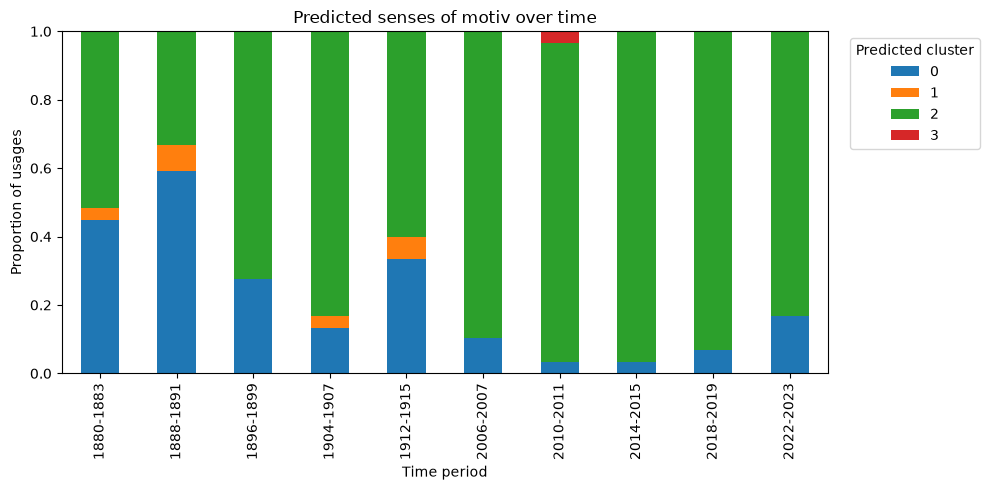

In [55]:
import matplotlib.pyplot as plt

motiv_predictions = hierarchical_development.loc[
    hierarchical_development["word"] == "motiv"
].copy()

motiv_predictions["cluster"] = motiv_predictions["label"].apply(
    lambda labels: labels[0]
)

sense_counts = pd.crosstab(
    motiv_predictions["period_label"],
    motiv_predictions["cluster"]
).sort_index()

sense_proportions = sense_counts.div(
    sense_counts.sum(axis=1), axis=0
)

sense_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Predicted senses of motiv over time")
plt.xlabel("Time period")
plt.ylabel("Proportion of usages")
plt.legend(title="Predicted cluster", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

#### Inspect examples from each predicted cluster to interpret the temporal pattern.

In [56]:
motiv_examples = data_by_word["motiv"].merge(
    motiv_predictions[
        ["word", "period_label", "sentence_id", "cluster"]
    ],
    on=["word", "period_label", "sentence_id"],
    validate="one_to_one"
)

for cluster, rows in motiv_examples.groupby("cluster"):
    print(f"\nCluster {cluster} — {len(rows)} usages")

    examples = rows.sample(
        n=min(4, len(rows)),
        random_state=42
    )

    for _, row in examples.iterrows():
        print(f"{row['year']}: {row['text']}")


Cluster 0 — 63 usages
2006: 39.000 barn från fem år till femte klass ska avgöra om en ny barnspårvagn ska få djungel- , rymd- eller spök- motiv .
1881: Ett annat ledande motiv återfinnes i det stora , derpå följande recitativet , hvari Gurnemanz skildrar detta ridderskaps och Graal-templets uppkomst .
1915: Någon » midsommardans » af det slag , som man ser på konstnärernas motiv frän just denna till:ti ; .-i , n " i kan oc . "
2022: Mellan 2005 och 2009 tog Moll tusentals bilder från Tibbleberget och resultatet är nu fem panoramabilder , fem meter långa och en meter höga , med motiv från de fyra årstiderna i dagsljus samt en sommarnattsbild .

Cluster 1 — 6 usages
1889: I lagförslagets motiv frambålles , att man skall följa de ledande grundsatserna för den tyska kolo nialpolitik , som riksdagen gillade 1884 och 1885 .
1906: Stämman beslöt att som sin förklaring uttala , att den , vidhållande i alla delar pröfningsnämndens motiv , ansåg , att pröfningsnämndens beslut borde få bestå .
1

#### Load multilingual BERT for a third embedding-model experiment.

In [57]:
mbert_name = "google-bert/bert-base-multilingual-cased"

mbert_tokenizer = AutoTokenizer.from_pretrained(
    mbert_name, use_fast=True
)

mbert_model = AutoModel.from_pretrained(
    mbert_name
).to(device).eval()

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 12548.92it/s]
[transformers] BertModel LOAD REPORT from: google-bert/bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


#### Extract mBERT vectors for the target word in each sentence.

In [58]:
def get_mbert_vector(row):
    text = row["text"]
    start = int(row["start"])
    end = int(row["end"])

    encoded = mbert_tokenizer(
        text,
        return_offsets_mapping=True,
        return_tensors="pt"
    )

    offsets = encoded.pop("offset_mapping")[0].tolist()

    target_tokens = []
    for i, (token_start, token_end) in enumerate(offsets):
        if token_end > token_start and token_start < end and token_end > start:
            target_tokens.append(i)

    if not target_tokens:
        raise ValueError(f"Target word not found: {row['sentence_id']}")

    if encoded["input_ids"].shape[1] > mbert_model.config.max_position_embeddings:
        raise ValueError(
            f"Sentence needs a shorter context window: {row['sentence_id']}"
        )

    encoded = encoded.to(device)

    with torch.no_grad():
        output = mbert_model(**encoded)

    target_vectors = output.last_hidden_state[0, target_tokens]
    vector = target_vectors.mean(dim=0)

    return vector.cpu().numpy()

#### Generate mBERT embeddings for the tuning words.

In [59]:
mbert_vectors_by_word = {}

for word in tqdm(tuning_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_mbert_vector(row))

    mbert_vectors_by_word[word] = np.stack(vectors)

100%|██████████| 7/7 [02:42<00:00, 23.23s/it]


#### Evaluate mBERT with average-linkage hierarchical clustering on the tuning words.

In [60]:
mbert_results = []

for cutoff in np.arange(0.1, 1.01, 0.1):
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(mbert_vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=float(cutoff)
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/mbert_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/mbert_tuning.jsonl")
    )

    mbert_results.append({
        "distance_cutoff": round(float(cutoff), 2),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

mbert_results = pd.DataFrame(mbert_results)
mbert_results

/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)
/Users/kmonroygill/Desktop/semantic-change-over-time/semeval2027-task3/evaluation.py:57: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, pvalue = spearmanr(gold_scores, predicted_scores)


,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.1,0.057135,-0.014467,196.571429
1,0.2,0.116475,0.434111,113.285714
2,0.3,0.382096,0.289134,26.857143
3,0.4,0.652425,0.362507,4.714286
4,0.5,0.685005,0.440079,2.000000
5,0.6,0.707728,0.320382,1.428571
6,0.7,0.707650,0.320382,1.142857
7,0.8,0.707600,0.000000,1.000000
8,0.9,0.707600,0.000000,1.000000
9,1.0,0.707600,0.000000,1.000000


#### Extract XLM-RoBERTa embeddings for the tuning words to compare embedding models using the same clustering method.

In [61]:
xlmr_vectors_by_word = {}

for word in tqdm(tuning_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_word_vector(row))

    xlmr_vectors_by_word[word] = np.stack(vectors)

100%|██████████| 7/7 [02:56<00:00, 25.16s/it]


#### Tune the hierarchical distance cutoff for XLM-RoBERTa and evaluate both metrics.

In [62]:
xlmr_results = []

for cutoff in [
    0.002, 0.004, 0.006, 0.008, 0.010,
    0.012, 0.015, 0.020, 0.025, 0.030
]:
    prediction_parts = []
    cluster_counts = []

    for word in tuning_words:
        vectors = normalize(xlmr_vectors_by_word[word])

        labels = AgglomerativeClustering(
            n_clusters=None,
            metric="cosine",
            linkage="average",
            distance_threshold=cutoff
        ).fit_predict(vectors)

        cluster_counts.append(len(np.unique(labels)))

        predictions = data_by_word[word][
            ["word", "period_label", "sentence_id"]
        ].copy()
        predictions["label"] = [[int(label)] for label in labels]
        prediction_parts.append(predictions)

    predictions = pd.concat(prediction_parts, ignore_index=True)
    predictions.to_json(
        "outputs/predictions/SV/xlmr_tuning.jsonl", orient="records", lines=True
    )

    clustering, change = evaluate_subtask1(
        Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
        Path("../outputs/predictions/SV/xlmr_tuning.jsonl")
    )

    xlmr_results.append({
        "distance_cutoff": round(float(cutoff), 3),
        "1a_F1": clustering["fcubed"],
        "1b_Spearman": change,
        "mean_clusters": np.mean(cluster_counts)
    })

xlmr_results = pd.DataFrame(xlmr_results)
xlmr_results

,distance_cutoff,1a_F1,1b_Spearman,mean_clusters
0,0.002,0.070292,0.546454,152.714286
1,0.004,0.241826,0.741071,57.714286
2,0.006,0.412018,0.710564,24.857143
3,0.008,0.503284,0.633340,13.285714
4,0.010,0.589068,0.702058,8.000000
5,0.012,0.635720,0.669818,5.428571
6,0.015,0.707587,0.554611,3.142857
7,0.020,0.705721,0.384987,1.857143
8,0.025,0.706317,0.212699,1.285714
9,0.030,0.707732,-0.169090,1.142857


#### Inspect XLM-RoBERTa cosine distances to choose a more appropriate clustering-cutoff range.

In [63]:
from sklearn.metrics import pairwise_distances

distance_summary = []

for word in tuning_words:
    vectors = normalize(xlmr_vectors_by_word[word])
    distances = pairwise_distances(vectors, metric="cosine")
    pairs = distances[np.triu_indices(len(vectors), k=1)]

    distance_summary.append({
        "word": word,
        "minimum": pairs.min(),
        "median": np.median(pairs),
        "90th_percentile": np.quantile(pairs, 0.90),
        "maximum": pairs.max()
    })

pd.DataFrame(distance_summary)

,word,minimum,median,90th_percentile,maximum
0,motiv,0.000376,0.009953,0.015483,0.036230
1,kvinna,0.000644,0.007636,0.011691,0.049524
2,fru,0.000646,0.008580,0.014934,0.033847
3,fröken,0.000000,0.007841,0.014165,0.025889
4,förort,0.000000,0.007896,0.012684,0.025736
5,skär,0.000637,0.010873,0.018279,0.032870
6,suga,0.000000,0.013419,0.029549,0.058293


#### Extract XLM-RoBERTa embeddings for the reserved words to evaluate the candidate selected on the tuning set.

In [64]:
for word in tqdm(heldout_words):
    vectors = []

    for _, row in data_by_word[word].iterrows():
        vectors.append(get_word_vector(row))

    xlmr_vectors_by_word[word] = np.stack(vectors)

100%|██████████| 3/3 [01:11<00:00, 23.76s/it]


#### Evaluate XLM-RoBERTa hierarchical clustering with cutoff 0.010 on the reserved words.

In [65]:
prediction_parts = []

for word in heldout_words:
    vectors = normalize(xlmr_vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=0.010
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

xlmr_validation = pd.concat(prediction_parts, ignore_index=True)
xlmr_validation.to_json(
    "outputs/predictions/SV/xlmr_validation.jsonl", orient="records", lines=True
)

xlmr_validation_scores, xlmr_validation_change = evaluate_subtask1(
    Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
    Path("../outputs/predictions/SV/xlmr_validation.jsonl")
)

print("XLM-RoBERTa 1a F1:", xlmr_validation_scores["fcubed"])
print("XLM-RoBERTa 1b Spearman:", xlmr_validation_change)

XLM-RoBERTa 1a F1: 0.7414627284833797
XLM-RoBERTa 1b Spearman: 0.5528905289052889


#### Evaluate XLM-RoBERTa’s shared sense assignments for both Subtask 1a and 1b.

In [66]:
prediction_parts = []

for word in sorted(data_by_word):
    vectors = normalize(xlmr_vectors_by_word[word])

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="cosine",
        linkage="average",
        distance_threshold=0.010
    ).fit_predict(vectors)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    prediction_parts.append(predictions)

xlmr_development = pd.concat(prediction_parts, ignore_index=True)
xlmr_development.to_json(
    "outputs/predictions/SV/development_xlmr.jsonl", orient="records", lines=True
)

xlmr_scores, xlmr_change = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("../outputs/predictions/SV/development_xlmr.jsonl")
)

pd.DataFrame([
    {
        "robert_model": "XL-LEXEME",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "robert_model": "XLM-RoBERTa",
        "1a_F1": xlmr_scores["fcubed"],
        "1b_Spearman": xlmr_change
    }
])

,model,1a_F1,1b_Spearman
0,XL-LEXEME,0.810829,0.562016
1,XLM-RoBERTa,0.634787,0.641340


#### Compare the selected system with the baseline and the alternative XLM-RoBERTa system on all development words.

In [67]:
final_comparison = pd.DataFrame([
    {
        "approach": "Single-cluster baseline",
        "1a_F1": baseline_scores["fcubed"],
        "1b_Spearman": np.nan
    },
    {
        "approach": "XL-LEXEME + hierarchical, cutoff 0.4",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "approach": "XLM-RoBERTa + hierarchical, cutoff 0.010",
        "1a_F1": xlmr_scores["fcubed"],
        "1b_Spearman": xlmr_change
    }
])

final_comparison.to_csv(
    "outputs/evaluations/SV/subtask1_development_comparison.csv", index=False
)

final_comparison

,approach,1a_F1,1b_Spearman
0,Single-cluster baseline,0.756342,NaN
1,"XL-LEXEME + hierarchical, cutoff 0.4",0.810829,0.562016
2,"XLM-RoBERTa + hierarchical, cutoff 0.010",0.634787,0.641340


#### Save embeddings and their matching usage rows for future experiments.

In [68]:
from zipfile import ZipFile

cache_folder = Path("../outputs/embeddings/subtask1_embedding_cache/SV")
cache_folder.mkdir(exist_ok=True)

for word, rows in data_by_word.items():
    rows[["word", "period_label", "sentence_id", "text", "start", "end"]].to_json(
        cache_folder / f"{word}_usages.jsonl",
        orient="records",
        lines=True,
        force_ascii=False
    )

for model_name, embeddings in [
    ("xl_lexeme", vectors_by_word),
    ("xlmr", xlmr_vectors_by_word),
    ("mbert", mbert_vectors_by_word)
]:
    np.savez_compressed(
        cache_folder / f"{model_name}_vectors.npz",
        **embeddings
    )

with ZipFile("../outputs/exports/subtask1_embedding_cache.zip", "w") as archive:
    for file in cache_folder.iterdir():
        archive.write(file, arcname=file.name)

print("Saved subtask1_embedding_cache.zip")

Saved subtask1_embedding_cache.zip


In [70]:
import requests
from io import BytesIO
from zipfile import ZipFile, is_zipfile

url = "https://www.codabench.org/datasets/download/id/936979/"
response = requests.get(url)
response.raise_for_status()

sample_file = BytesIO(response.content)

if not is_zipfile(sample_file):
    raise ValueError(
        "The download did not return a ZIP. "
        "Download the example through your logged-in Codabench account."
    )

with ZipFile(sample_file) as archive:
    for name in archive.namelist():
        print(name)

HTTPError: 503 Server Error: Service Unavailable for url: https://www.codabench.org/maintenance.html

In [ ]:
sample_file.seek(0)

with ZipFile(sample_file) as archive:
    with archive.open("SV_subtask1.jsonl") as file:
        example = json.loads(file.readline())

print(example)

#### Export the selected Subtask 1 predictions in the competition’s submission format.

In [ ]:
submission = hierarchical_development[
    ["word", "sentence_id", "label"]
].copy()

assert not submission.duplicated(["word", "sentence_id"]).any()

submission.to_json(
    "outputs/predictions/SV/SV_subtask1.jsonl",
    orient="records",
    lines=True,
    force_ascii=False
)

print("Saved outputs/predictions/SV/SV_subtask1.jsonl")
print("Total predictions:", len(submission))

#### Test density-based clustering, assigning each outlier its own label so unrelated outliers are not grouped together.

In [ ]:
from sklearn.cluster import HDBSCAN

def get_hdbscan_labels(vectors, min_cluster_size, min_samples):
    vectors = normalize(vectors)

    labels = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="cosine",
        algorithm="brute",
        allow_single_cluster=True
    ).fit_predict(vectors)

    outliers = np.flatnonzero(labels == -1)
    next_label = int(labels.max()) + 1

    for position in outliers:
        labels[position] = next_label
        next_label += 1

    return labels, len(outliers)

#### Compare HDBSCAN settings for sense clustering and semantic change, recording how many usages are treated as outliers.

In [ ]:
hdbscan_results = []

for min_cluster_size in [3, 5, 10, 15]:
    for min_samples in [2, 5]:
        prediction_parts = []
        cluster_counts = []
        total_outliers = 0

        for word in tuning_words:
            labels, outlier_count = get_hdbscan_labels(
                vectors_by_word[word],
                min_cluster_size,
                min_samples
            )

            total_outliers += outlier_count
            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "outputs/predictions/SV/hdbscan_tuning.jsonl", orient="records", lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
            Path("outputs/predictions/SV/hdbscan_tuning.jsonl")
        )

        hdbscan_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts),
            "outlier_usages": total_outliers
        })

hdbscan_results = pd.DataFrame(hdbscan_results)
hdbscan_results

#### Assign HDBSCAN outliers to the nearest detected cluster instead of creating singleton clusters.

In [ ]:
def get_hdbscan_reassigned_labels(
    vectors, min_cluster_size, min_samples
):
    vectors = normalize(vectors)

    labels = HDBSCAN(
        min_cluster_size=min_cluster_size,
        min_samples=min_samples,
        metric="cosine",
        algorithm="brute",
        allow_single_cluster=True
    ).fit_predict(vectors)

    outliers = labels == -1
    outlier_count = int(outliers.sum())
    clusters = np.unique(labels[~outliers])

    if len(clusters) == 0:
        return np.zeros(len(vectors), dtype=int), outlier_count

    if outlier_count > 0:
        centers = np.stack([
            vectors[labels == cluster].mean(axis=0)
            for cluster in clusters
        ])
        similarities = vectors[outliers] @ normalize(centers).T
        labels[outliers] = clusters[similarities.argmax(axis=1)]

    return labels, outlier_count

#### Test whether assigning outliers to nearby clusters improves HDBSCAN’s results.

In [ ]:
reassigned_results = []

for min_cluster_size in [3, 5, 10, 15]:
    for min_samples in [2, 5]:
        prediction_parts = []
        cluster_counts = []
        total_outliers = 0

        for word in tuning_words:
            labels, outlier_count = get_hdbscan_reassigned_labels(
                vectors_by_word[word],
                min_cluster_size,
                min_samples
            )

            total_outliers += outlier_count
            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "outputs/predictions/SV/hdbscan_reassigned_tuning.jsonl",
            orient="records",
            lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
            Path("outputs/predictions/SV/hdbscan_reassigned_tuning.jsonl")
        )

        reassigned_results.append({
            "min_cluster_size": min_cluster_size,
            "min_samples": min_samples,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts),
            "outlier_usages": total_outliers
        })

reassigned_results = pd.DataFrame(reassigned_results)
reassigned_results

#### Prepare and scale distances from both embedding models before combining them.

In [ ]:
from sklearn.metrics import pairwise_distances

lexeme_distances = {}
xlmr_distances = {}

lexeme_pairs = []
xlmr_pairs = []

for word in tuning_words:
    lexeme_vectors = vectors_by_word[word]
    xlmr_vectors = xlmr_vectors_by_word[word]

    assert len(lexeme_vectors) == len(xlmr_vectors) == len(data_by_word[word])

    lexeme_matrix = pairwise_distances(
        normalize(lexeme_vectors), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors), metric="cosine"
    )

    np.fill_diagonal(lexeme_matrix, 0)
    np.fill_diagonal(xlmr_matrix, 0)

    lexeme_distances[word] = lexeme_matrix
    xlmr_distances[word] = xlmr_matrix

    upper_triangle = np.triu_indices(len(lexeme_vectors), k=1)
    lexeme_pairs.append(lexeme_matrix[upper_triangle])
    xlmr_pairs.append(xlmr_matrix[upper_triangle])

lexeme_typical = np.median(np.concatenate(lexeme_pairs))
xlmr_typical = np.median(np.concatenate(xlmr_pairs))

if xlmr_typical <= 0:
    raise ValueError("Cannot scale distances with a zero median.")

xlmr_distance_scale = lexeme_typical / xlmr_typical

print("XLM-RoBERTa distance multiplier:", xlmr_distance_scale)

#### Compare blends of XL-LEXEME and XLM-RoBERTa distances using hierarchical clustering.

In [ ]:
blend_results = []

for lexeme_weight in [0.0, 0.25, 0.50, 0.75, 1.0]:
    for cutoff in [0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
        prediction_parts = []
        cluster_counts = []

        for word in tuning_words:
            distances = (
                lexeme_weight * lexeme_distances[word]
                + (1 - lexeme_weight)
                * xlmr_distance_scale
                * xlmr_distances[word]
            )

            distances = np.maximum(distances, 0)
            distances = (distances + distances.T) / 2
            np.fill_diagonal(distances, 0)

            labels = AgglomerativeClustering(
                n_clusters=None,
                metric="precomputed",
                linkage="average",
                distance_threshold=cutoff
            ).fit_predict(distances)

            cluster_counts.append(len(np.unique(labels)))

            predictions = data_by_word[word][
                ["word", "period_label", "sentence_id"]
            ].copy()
            predictions["label"] = [[int(label)] for label in labels]
            prediction_parts.append(predictions)

        predictions = pd.concat(prediction_parts, ignore_index=True)
        predictions.to_json(
            "outputs/predictions/SV/blend_tuning.jsonl", orient="records", lines=True
        )

        clustering, change = evaluate_subtask1(
            Path("../data/processed/subsets/SV/tuning_all_gold.jsonl"),
            Path("outputs/predictions/SV/blend_tuning.jsonl")
        )

        blend_results.append({
            "lexeme_weight": lexeme_weight,
            "cutoff": cutoff,
            "1a_F1": clustering["fcubed"],
            "1b_Spearman": change,
            "mean_clusters": np.mean(cluster_counts)
        })

blend_results = pd.DataFrame(blend_results)
blend_results.sort_values("1a_F1", ascending=False).head(15)

#### Evaluate the blended-distance candidate on the reserved words using the scaling learned from the tuning words.

In [ ]:
blend_prediction_parts = []

for word in heldout_words:
    lexeme_matrix = pairwise_distances(
        normalize(vectors_by_word[word]), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors_by_word[word]), metric="cosine"
    )

    distances = (
        0.5 * lexeme_matrix
        + 0.5 * xlmr_distance_scale * xlmr_matrix
    )

    distances = np.maximum(distances, 0)
    distances = (distances + distances.T) / 2
    np.fill_diagonal(distances, 0)

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="precomputed",
        linkage="average",
        distance_threshold=0.3
    ).fit_predict(distances)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    blend_prediction_parts.append(predictions)

blend_validation = pd.concat(
    blend_prediction_parts, ignore_index=True
)
blend_validation.to_json(
    "outputs/predictions/SV/blend_validation.jsonl", orient="records", lines=True
)

blend_scores, blend_change = evaluate_subtask1(
    Path("../data/processed/subsets/SV/heldout_all_gold.jsonl"),
    Path("outputs/predictions/SV/blend_validation.jsonl")
)

print("Blended robert_model 1a F1:", blend_scores["fcubed"])
print("Blended robert_model 1b Spearman:", blend_change)

#### Evaluate the fixed 50/50 distance blend across all development words.

In [ ]:
blend_parts = []

for word in sorted(data_by_word):
    lexeme_matrix = pairwise_distances(
        normalize(vectors_by_word[word]), metric="cosine"
    )
    xlmr_matrix = pairwise_distances(
        normalize(xlmr_vectors_by_word[word]), metric="cosine"
    )

    distances = (
        0.5 * lexeme_matrix
        + 0.5 * xlmr_distance_scale * xlmr_matrix
    )

    distances = np.maximum(distances, 0)
    distances = (distances + distances.T) / 2
    np.fill_diagonal(distances, 0)

    labels = AgglomerativeClustering(
        n_clusters=None,
        metric="precomputed",
        linkage="average",
        distance_threshold=0.3
    ).fit_predict(distances)

    predictions = data_by_word[word][
        ["word", "period_label", "sentence_id"]
    ].copy()
    predictions["label"] = [[int(label)] for label in labels]
    blend_parts.append(predictions)

blend_development = pd.concat(blend_parts, ignore_index=True)
blend_development.to_json(
    "outputs/predictions/SV/development_blended.jsonl", orient="records", lines=True
)

blend_development_scores, blend_development_change = evaluate_subtask1(
    Path("../data/processed/gold/SV/subtask1.jsonl"),
    Path("outputs/predictions/SV/development_blended.jsonl")
)

pd.DataFrame([
    {
        "approach": "XL-LEXEME alone",
        "1a_F1": hierarchical_scores["fcubed"],
        "1b_Spearman": hierarchical_change
    },
    {
        "approach": "50/50 blend",
        "1a_F1": blend_development_scores["fcubed"],
        "1b_Spearman": blend_development_change
    }
])

#### some simple eda - main sense and stuff (ty)

##### correct ones and sens #

In [ ]:
import pandas as pd

answers = pd.read_json("../data/raw/development-swedish/subtask1.jsonl", lines=True)
answers["sense"] = answers["label"].str[0]
answers.head()

#### seeing num of seses of each word and how common it is  & summary - by most mixed/jumbled to most centered on one sense

In [ ]:
all_senses = answers.explode("label")
counts = all_senses.groupby("word")["label"].value_counts()
sentences = answers["word"].value_counts()

summary = pd.DataFrame({
    "num_senses": all_senses.groupby("word")["label"].nunique(),
    "top_share": (counts.groupby("word").max() / sentences).round(2)
})
summary.sort_values("top_share")